# Task 4 model refresh
Copy the fitted winner because training images and labels are byte identical; link it to the new EDA card.

In [1]:
from pathlib import Path
import sys, json, joblib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "pipeline" / "save_data.py").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
SRC = ROOT / "src"
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
from src.pipeline.random_seed import set_seed
from src.pipeline.save_model import save_model
from src.pipeline.evaluate_model import evaluate_model
SEED = set_seed()
old_card = json.loads((SRC/'task4/save/t4_lgbm_31_tuned_features_r1.json').read_text(encoding='utf8'))
new_card = json.loads((SRC/'task4/data/eda/eda_1_v2.json').read_text(encoding='utf8'))
old_data_card = json.loads((SRC/old_card['data_card_path']).read_text(encoding='utf8'))
old_train = pd.read_parquet(SRC/old_data_card['splits']['train']['path'])
new_train = pd.read_parquet(SRC/new_card['splits']['train']['path'])
assert old_train.image_sha256.equals(new_train.image_sha256)
assert old_train['class'].equals(new_train['class'])
exclude={'id','class','image_sha256','width','height'}
feature_cols=[c for c in new_train if c not in exclude]
assert feature_cols == [c for c in old_train if c not in exclude]
y = new_train['class']
groups = new_train.image_sha256
splitter = StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
dev_idx,valid_idx=next(splitter.split(new_train,y,groups))
assert not (set(groups.iloc[dev_idx]) & set(groups.iloc[valid_idx]))
model=joblib.load(SRC/old_card['model_path'])
assert model.n_features_in_ == len(feature_cols)
X_valid=new_train.iloc[valid_idx][feature_cols].astype('float32')
pred=model.predict(X_valid)
score=f1_score(y.iloc[valid_idx],pred,average='macro')
old_eval=json.loads((SRC/'task4/save/t4_lgbm_31_tuned_features_r1-evaluation.json').read_text(encoding='utf8'))
assert abs(score-old_eval['score']) < 1e-12
print('Validation macro F1:',score)
name='t4_lgbm_31_tuned_features_r2'
if not (SRC/'task4/save'/f'{name}.json').exists():
    save_model(task=4,name=name,model=model,data_name='eda_1_v2',card={
        'idea':'Exact copy of previously fitted LightGBM model; train images and labels unchanged',
        'source_model':old_card['name'],'seed':SEED,'validation':'same stratified image-hash fold 1/5',
        'test_change':'new manifest IDs/order; no test fit'})
    evaluate_model(task=4,name=name,y_true=y.iloc[valid_idx],y_pred=pred,
        card={'split':'same stratified image-hash fold 1/5','source_model':old_card['name'],'seed':SEED})


Validation macro F1: 0.7716444859086071


In [2]:
# Copy every other fitted candidate; training images and labels are unchanged.
old_save = SRC / 'task4' / 'save'
old_cards = sorted(p for p in old_save.glob('*.json') if p.stem.endswith('_r1'))
assert len(old_cards) == 28
for path in old_cards:
    old = json.loads(path.read_text(encoding='utf8'))
    old_name = old['name']
    new_name = old_name.removesuffix('_r1') + '_r2'
    if new_name == name:
        continue
    data_name = {'eda_original_v1':'eda_original_v2', 'eda_1_v1':'eda_1_v2'}[old['data_name']]
    data_card = json.loads((SRC/'task4/data/eda'/f'{data_name}.json').read_text(encoding='utf8'))
    current_train = pd.read_parquet(SRC/data_card['splits']['train']['path'])
    old_data = json.loads((SRC/old['data_card_path']).read_text(encoding='utf8'))
    previous_train = pd.read_parquet(SRC/old_data['splits']['train']['path'])
    assert current_train.image_sha256.equals(previous_train.image_sha256)
    assert current_train['class'].equals(previous_train['class'])
    cols = [c for c in current_train if c not in exclude]
    assert cols == [c for c in previous_train if c not in exclude]
    if (old_save/f'{new_name}.json').exists():
        continue
    fitted = joblib.load(SRC/old['model_path'])
    predictions = fitted.predict(current_train.iloc[valid_idx][cols].astype('float32'))
    old_result = json.loads((old_save/f'{old_name}-evaluation.json').read_text(encoding='utf8'))
    current_score = f1_score(y.iloc[valid_idx], predictions, average='macro')
    assert abs(current_score-old_result['score']) < 1e-12, old_name
    save_model(task=4,name=new_name,model=fitted,data_name=data_name,
        card={'idea':'Exact copy of fitted candidate; train images and labels unchanged',
              'source_model':old_name,'seed':SEED,'test_change':'new manifest IDs/order; no test fit'})
    evaluate_model(task=4,name=new_name,y_true=y.iloc[valid_idx],y_pred=predictions,
        card={'split':'same stratified image-hash fold 1/5','source_model':old_name,'seed':SEED})
    print(new_name, round(current_score,5))
print('Refreshed models:',len(list(old_save.glob('*_r2.joblib'))))

Refreshed models: 28


## 2. Camera-image audit and pretrained image models

The current `eda_1_v2` card remains the dataset interface. Its image hashes and labels were checked against the current raw files by the EDA notebook. The instructor confirmed that Task 4 changed only `test.csv`; no new EDA artifact is needed. All fitting and augmentation below use `train/` images only. Validation is the existing stratified image-hash fold.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from src.task4.models.image_training import (
    CLASS_NAMES, fit_image_model, image_transform, save_checkpoint,
    load_checkpoint, predict,
)
SEED = set_seed(include_torch=True)
RAW = SRC / "task4" / "data" / "raw"
manifest = pd.read_csv(RAW / "train.csv")
assert manifest.columns.tolist() == ["id", "file_name", "label"]
assert manifest.id.tolist() == new_train.id.tolist()
assert (manifest.label.map(dict(enumerate(CLASS_NAMES))).tolist()
        == new_train["class"].tolist())
assert manifest.file_name.is_unique
image_paths = [(RAW / "train" / filename) for filename in manifest.file_name]
assert all(path.is_file() for path in image_paths)
label_codes = manifest.label.to_numpy(dtype=np.int64)
assert not (set(groups.iloc[dev_idx]) & set(groups.iloc[valid_idx]))
train_paths = [image_paths[i] for i in dev_idx]
valid_paths = [image_paths[i] for i in valid_idx]
train_labels, valid_labels = label_codes[dev_idx], label_codes[valid_idx]
print("Train/validation:", len(train_paths), len(valid_paths))
print("Counts by class:", np.bincount(train_labels), np.bincount(valid_labels))
print("Copied LightGBM macro F1:", f1_score(y.iloc[valid_idx], pred, average="macro"))
print(classification_report(y.iloc[valid_idx], pred, labels=CLASS_NAMES, zero_division=0))
print(confusion_matrix(y.iloc[valid_idx], pred, labels=CLASS_NAMES))

Train/validation: 25236 6310
Counts by class: [9943 3525 4477 4741 2550] [2486  882 1119 1185  638]
Copied LightGBM macro F1: 0.7716444859086071
              precision    recall  f1-score   support

       7-11k       0.81      0.93      0.87      2486
       fiveN       0.83      0.74      0.78       882
   freefried       0.79      0.77      0.78      1119
        pube       0.78      0.72      0.75      1185
     roblock       0.82      0.58      0.68       638

    accuracy                           0.80      6310
   macro avg       0.80      0.75      0.77      6310
weighted avg       0.80      0.80      0.80      6310

[[2318   33   48   64   23]
 [ 110  654   43   52   23]
 [ 143   32  862   75    7]
 [ 160   30  109  859   27]
 [ 138   42   30   57  371]]


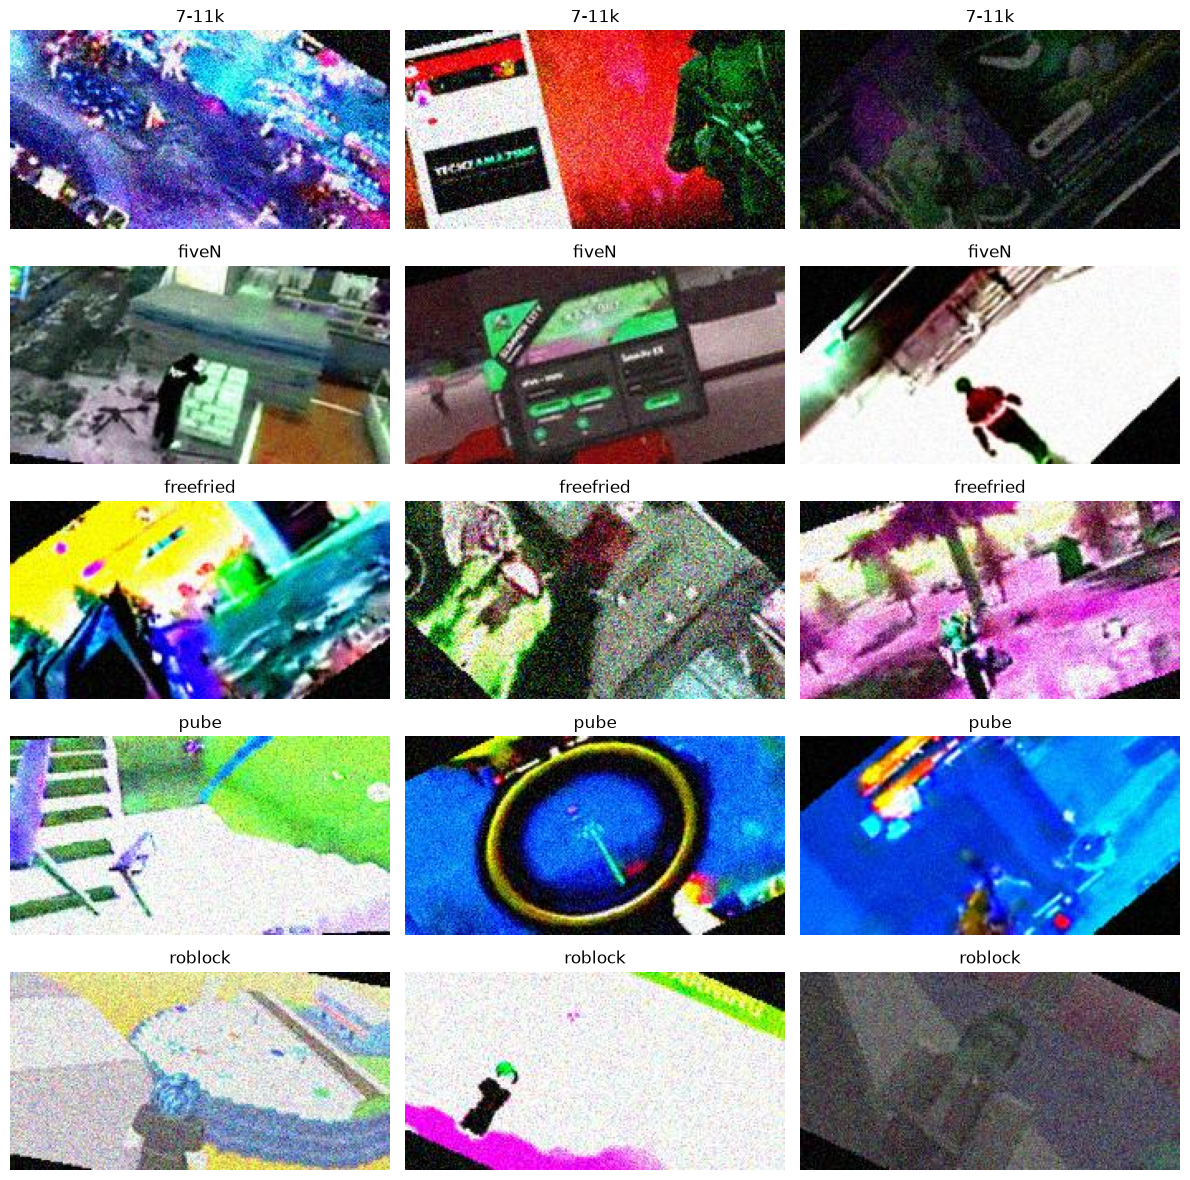

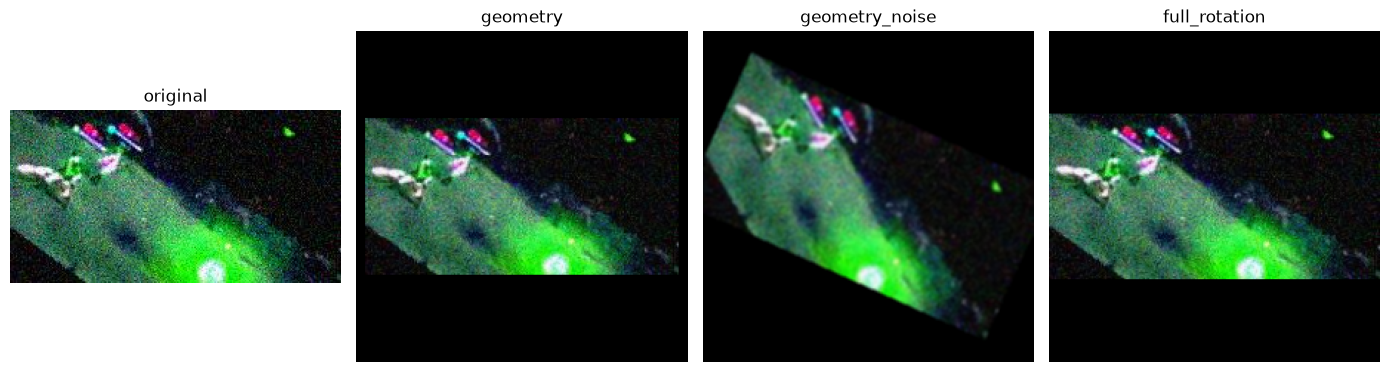

In [4]:
# Review actual camera photos and a few allowed transformations before fitting.
rng = np.random.default_rng(SEED)
selection = np.concatenate([rng.choice(np.flatnonzero(label_codes == k), 3, replace=False)
                            for k in range(len(CLASS_NAMES))])
fig, axes = plt.subplots(5, 3, figsize=(12, 12))
for axis, row in zip(axes.flat, selection):
    with Image.open(image_paths[row]) as image:
        axis.imshow(image.convert("RGB"))
    axis.set_title(CLASS_NAMES[label_codes[row]])
    axis.axis("off")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
with Image.open(train_paths[0]) as image:
    axes[0].imshow(image.convert("RGB"))
axes[0].set_title("original")
for axis, variant in zip(axes[1:], ("geometry", "geometry_noise", "full_rotation")):
    with Image.open(train_paths[0]) as image:
        transformed = image_transform(variant, train=True)(image.convert("RGB"))
    assert transformed.shape == (3, 224, 224)
    rgb = transformed.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    axis.imshow(np.clip(rgb, 0, 1))
    axis.set_title(variant)
for axis in axes: axis.axis("off")
plt.tight_layout()
plt.show()

### Frozen pretrained backbone

ResNet18 uses pretrained weights (permitted for Task 4). Its classifier is learned from the supplied train images. This is a quick signal before full fine-tuning.

In [5]:
name = "t4_resnet18_frozen_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, valid_pred, history = fit_image_model(
        train_paths, train_labels, valid_paths, valid_labels,
        variant="none", frozen=True, seed=SEED, epochs=5, batch_size=32,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Pretrained ResNet18 frozen backbone, trained classifier",
              "split": "image-hash grouped fold 1/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=name, y_true=valid_labels,
        y_pred=valid_pred, card={"split": "image-hash grouped fold 1/5", "seed": SEED})
    print(name, result["score"])
else:
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])

t4_resnet18_frozen_v2 0.7072763408580363


### Fine-tuning and augmentation ablations

Each cell starts from the same pretrained ResNet18 weights. The first uses the original photos. Later cells isolate geometric transforms, then add noise and blur. The full-rotation arm tests the proposed ±180° range separately. Validation photos are never augmented.

In [6]:
name = "t4_resnet18_finetune_plain_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, valid_pred, history = fit_image_model(
        train_paths, train_labels, valid_paths, valid_labels,
        variant="none", frozen=False, seed=SEED, epochs=8,
        batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Fine-tuned pretrained ResNet18 without added augmentation", "augmentation": "none",
              "split": "image-hash grouped fold 1/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=name, y_true=valid_labels,
        y_pred=valid_pred, card={"split": "image-hash grouped fold 1/5", "seed": SEED})
    print(name, result["score"])
else:
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])

t4_resnet18_finetune_plain_v2 0.9463704342684993


In [7]:
name = "t4_resnet18_finetune_geometry_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, valid_pred, history = fit_image_model(
        train_paths, train_labels, valid_paths, valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=8,
        batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Fine-tuned ResNet18 with rotation up to 50 degrees, perspective and scale", "augmentation": "geometry",
              "split": "image-hash grouped fold 1/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=name, y_true=valid_labels,
        y_pred=valid_pred, card={"split": "image-hash grouped fold 1/5", "seed": SEED})
    print(name, result["score"])
else:
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])

t4_resnet18_finetune_geometry_v2 0.9524649841895148


In [8]:
name = "t4_resnet18_finetune_geometry_noise_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, valid_pred, history = fit_image_model(
        train_paths, train_labels, valid_paths, valid_labels,
        variant="geometry_noise", frozen=False, seed=SEED, epochs=8,
        batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Fine-tuned ResNet18 with geometry, blur and sensor-like noise", "augmentation": "geometry_noise",
              "split": "image-hash grouped fold 1/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=name, y_true=valid_labels,
        y_pred=valid_pred, card={"split": "image-hash grouped fold 1/5", "seed": SEED})
    print(name, result["score"])
else:
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])

t4_resnet18_finetune_geometry_noise_v2 0.9553263067458475


In [9]:
name = "t4_resnet18_finetune_full_rotation_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, valid_pred, history = fit_image_model(
        train_paths, train_labels, valid_paths, valid_labels,
        variant="full_rotation", frozen=False, seed=SEED, epochs=8,
        batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Fine-tuned ResNet18 with rotation up to 180 degrees", "augmentation": "full_rotation",
              "split": "image-hash grouped fold 1/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=name, y_true=valid_labels,
        y_pred=valid_pred, card={"split": "image-hash grouped fold 1/5", "seed": SEED})
    print(name, result["score"])
else:
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])

t4_resnet18_finetune_full_rotation_v2 0.9493554422614766


### Compare the paired fold and inspect the winner

The model-selection fold is exploratory. An additional grouped fold should confirm a winner before treating it as the final submission model.

In [10]:
names = ["t4_lgbm_31_tuned_features_r2", "t4_resnet18_frozen_v2",
         "t4_resnet18_finetune_plain_v2", "t4_resnet18_finetune_geometry_v2",
         "t4_resnet18_finetune_geometry_noise_v2", "t4_resnet18_finetune_full_rotation_v2"]
index = json.loads((SRC / "task4" / "save" / "evaluation_index.json").read_text(encoding="utf-8"))
ranking = pd.DataFrame([{"model": name, "macro_F1": index["evaluations"][name]["score"]}
                        for name in names]).sort_values("macro_F1", ascending=False)
display(ranking)
selected_name = ranking.iloc[0]["model"]
print("Exploratory fold winner:", selected_name)
if selected_name.endswith("_v2") and selected_name.startswith("t4_resnet18"):
    import torch
    selected = load_checkpoint(SRC / "task4" / "save" / f"{selected_name}.pt")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    selected_pred = predict(selected.to(device), valid_paths, valid_labels, device)
    print(classification_report(valid_labels, selected_pred, target_names=CLASS_NAMES, zero_division=0))
    print(confusion_matrix(valid_labels, selected_pred))

,model,macro_F1
4,t4_resnet18_finetune_geometry_noise_v2,0.955326
3,t4_resnet18_finetune_geometry_v2,0.952465
5,t4_resnet18_finetune_full_rotation_v2,0.949355
2,t4_resnet18_finetune_plain_v2,0.946370
0,t4_lgbm_31_tuned_features_r2,0.771644
1,t4_resnet18_frozen_v2,0.707276


Exploratory fold winner: t4_resnet18_finetune_geometry_noise_v2


              precision    recall  f1-score   support

       7-11k       0.97      0.98      0.98      2486
       fiveN       0.98      0.94      0.96       882
   freefried       0.96      0.96      0.96      1119
        pube       0.98      0.94      0.96      1185
     roblock       0.88      0.96      0.92       638

    accuracy                           0.96      6310
   macro avg       0.95      0.96      0.96      6310
weighted avg       0.96      0.96      0.96      6310

[[2435    3    7    7   34]
 [  24  831    8    4   15]
 [  15    3 1079   12   10]
 [  16    7   23 1113   26]
 [  14    5    3    2  614]]


## 3. Fresh image-hash fold confirmation

The first fold selected geometry-plus-noise after several comparisons. The next paired grouped fold tests the plain, geometry, and geometry-plus-noise procedures on unseen validation photos. Fold-2 scores use their own metric name in the evaluation index so they cannot be ranked as the same holdout as fold 1.

In [11]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_fscore_support
fold2_dev, fold2_valid = list(splitter.split(new_train, y, groups))[1]
assert not (set(groups.iloc[fold2_dev]) & set(groups.iloc[fold2_valid]))
fold2_train_paths = [image_paths[i] for i in fold2_dev]
fold2_valid_paths = [image_paths[i] for i in fold2_valid]
fold2_train_labels = label_codes[fold2_dev]
fold2_valid_labels = label_codes[fold2_valid]
fold2_preds = {}
print("Fold 2 train/validation:", len(fold2_dev), len(fold2_valid))
print("Class counts:", np.bincount(fold2_train_labels), np.bincount(fold2_valid_labels))

Fold 2 train/validation: 25237 6309
Class counts: [9943 3525 4477 4741 2551] [2486  882 1119 1185  637]


In [12]:
name = "t4_lgbm_fold2_v2"
model_path = SRC / "task4" / "save" / f"{name}.joblib"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fold2_lgbm = clone(model)
    fold2_lgbm.fit(new_train.iloc[fold2_dev][feature_cols].astype("float32"), y.iloc[fold2_dev])
    fold2_pred_names = fold2_lgbm.predict(new_train.iloc[fold2_valid][feature_cols].astype("float32"))
    fold2_pred = np.array([CLASS_NAMES.index(value) for value in fold2_pred_names])
    save_model(task=4, name=name, model=fold2_lgbm, data_name="eda_1_v2",
        card={"idea": "Matched LightGBM baseline retrained on grouped fold 2",
              "source_model": "t4_lgbm_31_tuned_features_r2", "seed": SEED})
    result = evaluate_model(task=4, name=name, score=f1_score(fold2_valid_labels, fold2_pred, average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED})
    print(name, result["score"])
else:
    fold2_lgbm = joblib.load(model_path)
    fold2_pred_names = fold2_lgbm.predict(new_train.iloc[fold2_valid][feature_cols].astype("float32"))
    fold2_pred = np.array([CLASS_NAMES.index(value) for value in fold2_pred_names])
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])
fold2_preds[name] = fold2_pred

t4_lgbm_fold2_v2 0.7753189361432427


In [13]:
name = "t4_resnet18_finetune_plain_fold2_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, fold2_pred, history = fit_image_model(
        fold2_train_paths, fold2_train_labels, fold2_valid_paths, fold2_valid_labels,
        variant="none", frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Plain pretrained ResNet18 fine-tuning on grouped fold 2", "augmentation": "none",
              "split": "image-hash grouped fold 2/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    class_f1 = precision_recall_fscore_support(fold2_valid_labels, fold2_pred,
        labels=np.arange(5), zero_division=0)[2]
    result = evaluate_model(task=4, name=name,
        score=f1_score(fold2_valid_labels, fold2_pred, average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED,
              "class_F1": dict(zip(CLASS_NAMES, class_f1.tolist()))})
    print(name, result["score"])
else:
    import torch
    fitted = load_checkpoint(model_path)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fold2_pred = predict(fitted.to(device), fold2_valid_paths, fold2_valid_labels, device)
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])
fold2_preds[name] = fold2_pred

t4_resnet18_finetune_plain_fold2_v2 0.949620803616499


In [14]:
name = "t4_resnet18_finetune_geometry_fold2_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, fold2_pred, history = fit_image_model(
        fold2_train_paths, fold2_train_labels, fold2_valid_paths, fold2_valid_labels,
        variant="geometry", frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Geometry-augmented pretrained ResNet18 fine-tuning on grouped fold 2", "augmentation": "geometry",
              "split": "image-hash grouped fold 2/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    class_f1 = precision_recall_fscore_support(fold2_valid_labels, fold2_pred,
        labels=np.arange(5), zero_division=0)[2]
    result = evaluate_model(task=4, name=name,
        score=f1_score(fold2_valid_labels, fold2_pred, average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED,
              "class_F1": dict(zip(CLASS_NAMES, class_f1.tolist()))})
    print(name, result["score"])
else:
    import torch
    fitted = load_checkpoint(model_path)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fold2_pred = predict(fitted.to(device), fold2_valid_paths, fold2_valid_labels, device)
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])
fold2_preds[name] = fold2_pred

t4_resnet18_finetune_geometry_fold2_v2 0.9552765801501646


In [15]:
name = "t4_resnet18_finetune_geometry_noise_fold2_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, fold2_pred, history = fit_image_model(
        fold2_train_paths, fold2_train_labels, fold2_valid_paths, fold2_valid_labels,
        variant="geometry_noise", frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Geometry, blur and noise pretrained ResNet18 fine-tuning on grouped fold 2", "augmentation": "geometry_noise",
              "split": "image-hash grouped fold 2/5", "seed": SEED,
              "epochs": history, "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    class_f1 = precision_recall_fscore_support(fold2_valid_labels, fold2_pred,
        labels=np.arange(5), zero_division=0)[2]
    result = evaluate_model(task=4, name=name,
        score=f1_score(fold2_valid_labels, fold2_pred, average="macro"),
        metric_name="macro_F1_grouped_fold2", higher_is_better=True,
        card={"split": "image-hash grouped fold 2/5", "seed": SEED,
              "class_F1": dict(zip(CLASS_NAMES, class_f1.tolist()))})
    print(name, result["score"])
else:
    import torch
    fitted = load_checkpoint(model_path)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fold2_pred = predict(fitted.to(device), fold2_valid_paths, fold2_valid_labels, device)
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])
fold2_preds[name] = fold2_pred

t4_resnet18_finetune_geometry_noise_fold2_v2 0.9434598270697565


In [16]:
fold2_ranking = pd.DataFrame([
    {"model": name, "macro_F1": f1_score(fold2_valid_labels, values, average="macro")}
    for name, values in fold2_preds.items()
]).sort_values("macro_F1", ascending=False)
display(fold2_ranking)
for name, values in fold2_preds.items():
    print(name, "per-class F1:",
          dict(zip(CLASS_NAMES, precision_recall_fscore_support(
              fold2_valid_labels, values, labels=np.arange(5), zero_division=0)[2].round(4))))
fold1_scores = dict(zip(ranking.model, ranking.macro_F1))
paired = pd.DataFrame([
    {"variant": variant,
     "fold1_macro_F1": fold1_scores[f"t4_resnet18_finetune_{variant}_v2"],
     "fold2_macro_F1": f1_score(fold2_valid_labels,
         fold2_preds[f"t4_resnet18_finetune_{variant}_fold2_v2"], average="macro")}
    for variant in ("plain", "geometry", "geometry_noise")
])
paired["mean_two_folds"] = paired[["fold1_macro_F1", "fold2_macro_F1"]].mean(axis=1)
display(paired.sort_values("mean_two_folds", ascending=False))
confirmed_variant = paired.sort_values("mean_two_folds", ascending=False).iloc[0].variant
confirmed_variant = "none" if confirmed_variant == "plain" else confirmed_variant
print("Variant selected for fold 3:", confirmed_variant)

,model,macro_F1
2,t4_resnet18_finetune_geometry_fold2_v2,0.955277
1,t4_resnet18_finetune_plain_fold2_v2,0.949621
3,t4_resnet18_finetune_geometry_noise_fold2_v2,0.943460
0,t4_lgbm_fold2_v2,0.775319


t4_lgbm_fold2_v2 per-class F1: {'7-11k': np.float64(0.8636), 'fiveN': np.float64(0.7753), 'freefried': np.float64(0.7814), 'pube': np.float64(0.7586), 'roblock': np.float64(0.6977)}
t4_resnet18_finetune_plain_fold2_v2 per-class F1: {'7-11k': np.float64(0.9738), 'fiveN': np.float64(0.9446), 'freefried': np.float64(0.9599), 'pube': np.float64(0.9522), 'roblock': np.float64(0.9176)}
t4_resnet18_finetune_geometry_fold2_v2 per-class F1: {'7-11k': np.float64(0.9769), 'fiveN': np.float64(0.9534), 'freefried': np.float64(0.9675), 'pube': np.float64(0.9613), 'roblock': np.float64(0.9173)}
t4_resnet18_finetune_geometry_noise_fold2_v2 per-class F1: {'7-11k': np.float64(0.9694), 'fiveN': np.float64(0.9475), 'freefried': np.float64(0.9596), 'pube': np.float64(0.9437), 'roblock': np.float64(0.8971)}


,variant,fold1_macro_F1,fold2_macro_F1,mean_two_folds
1,geometry,0.952465,0.955277,0.953871
2,geometry_noise,0.955326,0.943460,0.949393
0,plain,0.946370,0.949621,0.947996


Variant selected for fold 3: geometry


### One more grouped fold for the selected procedure

The variant choice uses folds 1 and 2. Fold 3 is a further check of the fixed choice; it is not compared as a new search among variants.

In [17]:
fold3_dev, fold3_valid = list(splitter.split(new_train, y, groups))[2]
assert not (set(groups.iloc[fold3_dev]) & set(groups.iloc[fold3_valid]))
fold3_train_paths = [image_paths[i] for i in fold3_dev]
fold3_valid_paths = [image_paths[i] for i in fold3_valid]
fold3_train_labels = label_codes[fold3_dev]
fold3_valid_labels = label_codes[fold3_valid]
name = f"t4_resnet18_{confirmed_variant}_fold3_v2"
model_path = SRC / "task4" / "save" / f"{name}.pt"
card_path = SRC / "task4" / "save" / f"{name}.json"
eval_path = SRC / "task4" / "save" / f"{name}-evaluation.json"
if not (card_path.exists() and model_path.exists() and eval_path.exists()):
    assert not any(path.exists() for path in (model_path, card_path, eval_path)), "Inspect incomplete artifact"
    fitted, fold3_pred, history = fit_image_model(
        fold3_train_paths, fold3_train_labels, fold3_valid_paths, fold3_valid_labels,
        variant=confirmed_variant, frozen=False, seed=SEED, epochs=8, batch_size=32, patience=3,
    )
    save_model(task=4, name=name, model=fitted, data_name="eda_1_v2",
        saver=save_checkpoint, extension="pt",
        card={"idea": "Selected pretrained ResNet18 variant on grouped fold 3",
              "augmentation": confirmed_variant, "split": "image-hash grouped fold 3/5",
              "seed": SEED, "epochs": history,
              "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    class_f1 = precision_recall_fscore_support(fold3_valid_labels, fold3_pred,
        labels=np.arange(5), zero_division=0)[2]
    result = evaluate_model(task=4, name=name,
        score=f1_score(fold3_valid_labels, fold3_pred, average="macro"),
        metric_name="macro_F1_grouped_fold3", higher_is_better=True,
        card={"split": "image-hash grouped fold 3/5", "seed": SEED,
              "class_F1": dict(zip(CLASS_NAMES, class_f1.tolist()))})
    print(name, result["score"])
else:
    import torch
    fitted = load_checkpoint(model_path)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fold3_pred = predict(fitted.to(device), fold3_valid_paths, fold3_valid_labels, device)
    print(name, json.loads(eval_path.read_text(encoding="utf-8"))["score"])
selected_fold1 = fold1_scores[f"t4_resnet18_finetune_{'plain' if confirmed_variant == 'none' else confirmed_variant}_v2"]
selected_fold2 = f1_score(fold2_valid_labels,
    fold2_preds[f"t4_resnet18_finetune_{'plain' if confirmed_variant == 'none' else confirmed_variant}_fold2_v2"], average="macro")
selected_fold3 = f1_score(fold3_valid_labels, fold3_pred, average="macro")
print("Selected procedure scores, folds 1-3:", selected_fold1, selected_fold2, selected_fold3)
print("Mean:", np.mean([selected_fold1, selected_fold2, selected_fold3]))

t4_resnet18_geometry_fold3_v2 0.9556813654889463
Selected procedure scores, folds 1-3: 0.9524649841895148 0.9552765801501646 0.9556813654889463
Mean: 0.9544743099428752


## 4. Fit the selected procedure on all labeled Train images

Geometry was stronger than plain fine-tuning on both paired folds. Noise and blur did not repeat their fold-1 benefit. The fixed seven-epoch full fit is the median of the geometry best epochs on grouped folds 1–3 (7, 8, 7). The three-fold mean is an estimate of the selected procedure, not a validation score measured on the full-data model.

In [18]:
from src.task4.models.image_training import fit_full_image_model
full_name = "t4_resnet18_geometry_full_v2"
full_path = SRC / "task4" / "save" / f"{full_name}.pt"
full_card_path = SRC / "task4" / "save" / f"{full_name}.json"
full_eval_path = SRC / "task4" / "save" / f"{full_name}-evaluation.json"
fold_scores = [selected_fold1, selected_fold2, selected_fold3]
assert confirmed_variant == "geometry"
assert len(fold_scores) == 3
if not (full_path.exists() and full_card_path.exists() and full_eval_path.exists()):
    assert not any(path.exists() for path in (full_path, full_card_path, full_eval_path)), "Inspect incomplete artifact"
    full_model, full_history = fit_full_image_model(
        image_paths, label_codes, variant="geometry", seed=SEED,
        epochs=7, batch_size=32,
    )
    save_model(task=4, name=full_name, model=full_model,
        data_name="eda_1_v2", saver=save_checkpoint, extension="pt",
        card={"idea": "Selected pretrained ResNet18 trained on all labeled Task 4 images",
              "augmentation": "geometry", "train_rows": len(image_paths), "seed": SEED,
              "epochs": 7, "training_history": full_history,
              "selection": "geometry won paired folds 1-2 and scored 0.95568 on fold 3",
              "inference": "image_training.load_checkpoint; image_transform('none', train=False)"})
    result = evaluate_model(task=4, name=full_name,
        score=float(np.mean(fold_scores)), metric_name="macro_F1_grouped_cv3",
        higher_is_better=True,
        card={"estimate_for": "selected training procedure, not the full fit itself",
              "folds": [1, 2, 3], "fold_scores": fold_scores, "seed": SEED,
              "selection_note": "variant selected using folds 1-2; fold 3 is a check"})
    print(full_name, result["score"])
else:
    print(full_name, json.loads(full_eval_path.read_text(encoding="utf-8"))["score"])

full geometry epoch 1/7: loss=0.4808


full geometry epoch 2/7: loss=0.2472


full geometry epoch 3/7: loss=0.1852


full geometry epoch 4/7: loss=0.1554


full geometry epoch 5/7: loss=0.1298


full geometry epoch 6/7: loss=0.1147


full geometry epoch 7/7: loss=0.1065


t4_resnet18_geometry_full_v2 0.9544743099428752


### Predict Test once with the saved full-data checkpoint

Test is used only for final prediction and format checks. The linked EDA test card supplies the current `ANS` IDs and order; the raw `test.csv` supplies the corresponding filenames. `build_sample_submission` records model and dataset lineage.

In [19]:
from src.pipeline.build_sample_submission import build_sample_submission
import torch
test_card = json.loads((SRC / "task4" / "data" / "eda" / "eda_1_v2.json").read_text(encoding="utf-8"))
test_saved = pd.read_parquet(SRC / test_card["splits"]["test"]["path"])
test_manifest = pd.read_csv(RAW / "test.csv")
assert test_manifest.columns.tolist() == ["id", "file_name", "label"]
assert test_manifest.label.isna().all()
assert test_manifest.id.tolist() == test_saved.id.tolist()
assert len(test_manifest) == 25_889 and test_manifest.id.is_unique
test_paths = [RAW / "test" / filename for filename in test_manifest.file_name]
assert all(path.is_file() for path in test_paths)
submission_name = "t4_resnet18_geometry_full_v2"
submission_csv = SRC / "task4" / "submission" / f"{submission_name}.csv"
submission_card = SRC / "task4" / "submission" / f"{submission_name}.json"
if not (submission_csv.exists() and submission_card.exists()):
    assert not (submission_csv.exists() or submission_card.exists()), "Inspect incomplete submission artifact"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    info = build_sample_submission(
        task=4, name=submission_name, model_name=full_name,
        card={"idea": "Selected geometry ResNet18; Test prediction only",
              "cv3_macro_F1": float(np.mean(fold_scores)), "seed": SEED},
        loader=lambda path: load_checkpoint(Path(path)),
        predict_fn=lambda fitted, _: predict(fitted.to(device), test_paths, None, device),
    )
    print(info["submission_path"], info["rows"])
part = pd.read_csv(submission_csv, sep="|")
assert part.columns.tolist() == ["id", "task4"]
assert part.id.tolist() == test_manifest.id.tolist()
assert set(part.task4) <= set(range(5))
print("Test prediction counts:", part.task4.value_counts().sort_index().to_dict())

task4/submission/t4_resnet18_geometry_full_v2.csv 25889
Test prediction counts: {0: 4748, 1: 6024, 2: 3572, 3: 6641, 4: 4904}
